# Year 3 of the 1 Nov 2026 start: drift extrapolation, base period and P(La Niña)

First notebook of `nov2026_outlook/` (the 1 Nov 2026 case): how the lead-time climatology (drift correction)
of the third year of this 36-month start is built, and how much the La Niña outlook depends on it.

The Reanalysis (BruteForce) hindcasts that define the lead-dependent drift run 24 months.
`rc.extend_leads` gives leads 24-35 the drift of the lead 12 months earlier (same target month), i.e. it
holds the drift fixed after year 2. The drift-corrected Niño3.4 ensemble mean then jumps by about +0.4 °C at
lead 24 (Oct to Nov 2028). Two concerns before quoting P(La Niña 2028/29):

1. **Year-3 drift.** If the drift is still changing in year 2, holding it under-corrects year 3, warms it
   and lowers P(La Niña 2028/29). Proposed: per target month *m*,
   $d_3(m) = d_2(m) + r\,[d_2(m) - d_1(m)]$ ($d_1, d_2$: drift at leads 0-11 and 12-23; $r = 0$ holds,
   $r = 1$ continues linearly, fitted $r = e^{-12/T}$ from $d(L) = s(m_L) + A\,e^{-L/T}$), with the check
   that the lead-24 step disappears.
2. **Base period and trend.** Drift and observed anomalies use 1981-2010; the warming since biases a
   2026-2029 Niño3.4 anomaly warm. Proposed: the relative Niño3.4 (minus the 20°S-20°N ocean mean, scaled
   as CPC's RONI), and for the standard index a drift from the 1991-2018 starts with the 1991-2020
   climatology.

**What this notebook shows** (index space: Niño3.4 and the tropical ocean mean of `TS`, masks as in the
other notebooks; 30 pooled members):

1. The drift by lead, and how it changes from year 1 to year 2 month by month.
2. Where the lead-24 step comes from (raw forecast, observed climatology, drift).
3. Year-3 drift methods, including the proposed one and an *adjusted* version that leaves out the
   initial-adjustment leads, and the step each leaves.
4. P(La Niña) for DJF 2027/28, 2028/29 and both, for every index × base × method.
5. The tropical warming behind the base-period concern.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

# diagnostic/ (the shared util package) is the first parent folder holding util/rtenso_case.py
DIAG_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "util" / "rtenso_case.py").is_file())
sys.path.insert(0, str(DIAG_ROOT))
from util import rtenso_case as rc
from esp_lab.utils.netcdf_utils import atomic_to_netcdf, load_netcdf

### Run controls

In [2]:
NOTEBOOK = "nov2026_outlook/01_year3_drift_sensitivity"   # outputs: rc.OUTPUT_ROOT/nov2026_outlook/01_year3_drift_sensitivity/{figures,data}/
FORCE_COMPUTE = False   # False: read valid caches, build missing or stale ones; True: recompute this notebook's products
                        # (shared Reanalysis/observation/ERA5 caches are reused; set rc.REBUILD_REFERENCE = True to redo them)
derivation_mode = "rebuild" if FORCE_COMPUTE else "auto"

YEAR, INIT = 2026, 11                       # the extended start (rc.EXTENDED_STARTS)
NLEAD_REF = rc.NLEAD                        # Reanalysis length (24)
NLEAD = rc.start_nlead(YEAR, INIT)          # 36
REF_YEARS = (1981, 2018)                    # Reanalysis 1 Nov starts read (every year)
BASES = {                                   # drift start years and observed climatology years
    "1981-2010": {"starts": (1981, 2010), "clim": (1981, 2010)},
    "1991-2018/2020": {"starts": (1991, 2018), "clim": (1991, 2020)},
}
INDICES = {"Nino3.4": "Niño3.4", "Relative": "Relative Niño3.4 (RONI-scaled)"}
ADJUST_LEADS = 3                            # leads 0-2 are the initial adjustment: their year-1-to-2 change is not used
# Year-3 drift methods: (r, adjusted). r: number or "fit"; adjusted: year-to-year change from leads >= ADJUST_LEADS only
METHODS = {
    "hold (r = 0)": (0.0, False),           # current rc.extend_leads
    "per-month, r = 1": (1.0, False),       # the proposed formula, linear
    "adjusted, r = 0.5": (0.5, True),
    "adjusted, fitted r": ("fit", True),
    "adjusted, r = 1": (1.0, True),
}
COLORS = dict(zip(METHODS, ["tab:red", "tab:orange", "tab:olive", "tab:purple", "tab:blue"]))
POOL = {name: rc.CASES[name]["case_prefix"] for name in rc.POOLED_CASES}   # 30 members for this start
NINO_BOX = rc.NINO_REGIONS["Nino3.4"]
TROPICAL_BOX = (0.0, 360.0, -20.0, 20.0)    # ocean points 20S-20N (as the RONI of enso/01_enso_plume)
OBS_PRODUCT = "HadISST1.1"
THRESHOLD = -0.5                            # La Niña: DJF mean at or below
WINTERS = {"2026/27": 1, "2027/28": 13, "2028/29": 25}   # first lead (Dec) of each DJF for a 1 Nov start
T_GRID = np.geomspace(1.0, 600.0, 600)      # e-folding times (months) scanned by the exponential fit
N_BOOT = 500                                # bootstrap resamples of the start years

DATA_DIR = rc.output_dir(NOTEBOOK, "data")
plt.rcParams.update({"font.size": 12, "axes.grid": True, "grid.alpha": 0.3})


def save(fig, *parts):
    print(rc.save_figure(fig, NOTEBOOK, *parts, dpi=200))

### Load: Niño3.4 and tropical-mean `TS` (cached)

Ensemble means of the Reanalysis 1 Nov starts (year, lead), the pooled members of the 1 Nov 2026 start
(member, lead) and HadISST 1.1 (time), all absolute °C. Built once (about 10 minutes of reading) and cached
under `S2D_DIAG_ROOT/RTENSO2026_pool/nino_drift/`.

In [3]:
%%time
CACHE = rc.diag_dir("RTENSO2026_pool", "nino_drift",
                    f"nino34_trop_init{INIT:02d}_ref{REF_YEARS[0]}-{REF_YEARS[1]}_y{YEAR}_l{NLEAD}_{OBS_PRODUCT}_v1.nc")
EXPECTED = {"ref_years": f"{REF_YEARS[0]}-{REF_YEARS[1]}", "year": YEAR, "init": INIT, "nlead": NLEAD,
            "pool": ",".join(POOL), "obs": OBS_PRODUCT}


def build_indices():
    ocean = rc.land_fraction() < 0.5
    idx = lambda da: (rc.box_mean(da, NINO_BOX).load(), rc.box_mean(da.where(ocean), TROPICAL_BOX).load())
    rn, rt, years = [], [], []
    for y in range(REF_YEARS[0], REF_YEARS[1] + 1):
        ens = rc.open_hindcast(rc.REFERENCE["case_prefix"], y, INIT, "TS")
        if ens is None:
            continue
        n, t = idx(ens.mean("member"))
        rn.append(n.values), rt.append(t.values), years.append(y)
    fn, ft, members = [], [], []
    for name, prefix in POOL.items():
        ens = rc.open_hindcast(prefix, YEAR, INIT, "TS")
        n, t = idx(ens)
        fn.append(n.values), ft.append(t.values)
        members += [f"{rc.CASES[name]['short']}:{m}" for m in ens["member"].values]
    obs = rc.obs_monthly("TS", years=(REF_YEARS[0], YEAR), mode=derivation_mode, product=OBS_PRODUCT)
    on, ot = idx(obs)
    ds = xr.Dataset(
        {"ref_nino": (("year", "lead"), np.array(rn)), "ref_trop": (("year", "lead"), np.array(rt)),
         "fc_nino": (("member", "flead"), np.concatenate(fn)), "fc_trop": (("member", "flead"), np.concatenate(ft)),
         "obs_nino": ("time", on.values), "obs_trop": ("time", ot.values)},
        coords={"year": years, "lead": np.arange(NLEAD_REF), "member": members, "flead": np.arange(NLEAD),
                "time": [f"{t.year:04d}-{t.month:02d}" for t in obs["time"].to_index()]})
    ds.attrs.update(EXPECTED, units="degC")
    return ds


if derivation_mode != "rebuild" and CACHE.is_file() and all(
        str(load_netcdf(CACHE).attrs.get(k)) == str(v) for k, v in EXPECTED.items()):
    D = load_netcdf(CACHE)
else:
    D = build_indices()
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    atomic_to_netcdf(D, CACHE)
print(f"Reanalysis Nov starts {int(D.year[0])}-{int(D.year[-1])} ({D.sizes['year']}), "
      f"{D.sizes['member']} forecast members, HadISST {str(D.time.values[0])} to {str(D.time.values[-1])}")

Reanalysis Nov starts 1981-2018 (38), 30 forecast members, HadISST 1981-01 to 2026-09
CPU times: user 729 ms, sys: 412 ms, total: 1.14 s
Wall time: 5.25 s


### Helpers

Drift = Reanalysis ensemble mean minus HadISST at the same verification month, averaged over the start
years of a base. Anomaly = forecast − (observed climatology of the target month + drift). For the relative
index every term is Niño3.4 minus the tropical mean, then scaled by σ(ONI)/σ(relative) of the base-period
observations (CPC's RONI).

In [4]:
OBS = pd.Series(D["obs_nino"].values, index=pd.PeriodIndex(D["time"].values, freq="M"))
OBS_T = pd.Series(D["obs_trop"].values, index=OBS.index)
MONTH = [(INIT - 1 + L) % 12 + 1 for L in range(NLEAD)]
MLAB = "JFMAMJJASOND"


def target(y, lead):
    return pd.Period(year=y, month=INIT, freq="M") + int(lead)


def series(kind):
    # (Reanalysis (year, lead), forecast (member, lead), obs series) for "Nino3.4" or "Relative"
    if kind == "Nino3.4":
        return D["ref_nino"], D["fc_nino"], OBS
    return D["ref_nino"] - D["ref_trop"], D["fc_nino"] - D["fc_trop"], OBS - OBS_T


def drift_per_year(kind, starts):
    ref, _, obs = series(kind)
    years = [y for y in ref["year"].values if starts[0] <= y <= starts[1]]
    return np.array([[float(ref.sel(year=y, lead=L)) - obs[target(y, L)] for L in range(NLEAD_REF)] for y in years]), years


def month_clim(obs, clim):
    sel = obs[(obs.index.year >= clim[0]) & (obs.index.year <= clim[1])]
    return sel.groupby(sel.index.month).mean()


def fit_r(d, first=0):
    # d(L) = s(month of L) + A exp(-L/T) over leads first..23: least squares over T_GRID -> r = exp(-12/T)
    L = np.arange(first, len(d))
    X0 = np.eye(12)[(INIT - 1 + L) % 12]
    best = None
    for T in T_GRID:
        X = np.column_stack([X0, np.exp(-L / T)])
        coef, *_ = np.linalg.lstsq(X, d[first:], rcond=None)
        sse = float(np.sum((X @ coef - d[first:]) ** 2))
        if best is None or sse < best[0]:
            best = (sse, T)
    return float(np.exp(-12.0 / best[1])), best[1]


def year_change(d, adjusted):
    # d2 - d1 by target month (leads 12-23 minus 0-11); adjusted: the initial-adjustment leads take the
    # mean change of the later ones
    delta = d[12:24] - d[:12]
    if adjusted:
        delta = np.where(np.arange(12) < ADJUST_LEADS, delta[ADJUST_LEADS:].mean(), delta)
    return delta


def extend(d, method):
    r, adjusted = METHODS[method]
    if r == "fit":
        r = fit_r(d, ADJUST_LEADS if adjusted else 0)[0]
    return np.r_[d[:NLEAD_REF], d[12:24] + r * year_change(d, adjusted)], r


def roni_scale(clim):
    an = OBS - month_clim(OBS, clim).reindex(OBS.index.month).values
    at = OBS_T - month_clim(OBS_T, clim).reindex(OBS_T.index.month).values
    sel = (an.index.year >= clim[0]) & (an.index.year <= clim[1])
    return float(an[sel].rolling(3, center=True).mean().std() / (an - at)[sel].rolling(3, center=True).mean().std())


def forecast_anomaly(kind, base, method):
    # pooled members (member, lead) of the drift-corrected anomaly, and the r used
    _, fc, obs = series(kind)
    per_year, _ = drift_per_year(kind, BASES[base]["starts"])
    d, r = extend(per_year.mean(0), method)
    clim = month_clim(obs, BASES[base]["clim"])
    anom = fc.values - (clim.loc[MONTH].values + d)[None, :]
    if kind == "Relative":
        anom = anom * roni_scale(BASES[base]["clim"])
    return anom, r


def djf(anom, first):
    return anom[:, first:first + 3].mean(1)

### 1. The drift and how it changes from year 1 to year 2

Top: drift by lead (thin: start years). Bottom: the year-1-to-2 change $d_2 - d_1$ by target month. Bars
for the initial-adjustment months (leads 0-2: Nov-Jan of year 1) are hatched. At lead 0 the run has
barely drifted, so its change to lead 12 mixes the initial adjustment with the slow drift; extrapolating
it would carry the initial adjustment into year 3.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/01_year3_drift_sensitivity/figures/fig_year3_drift_year_change.png


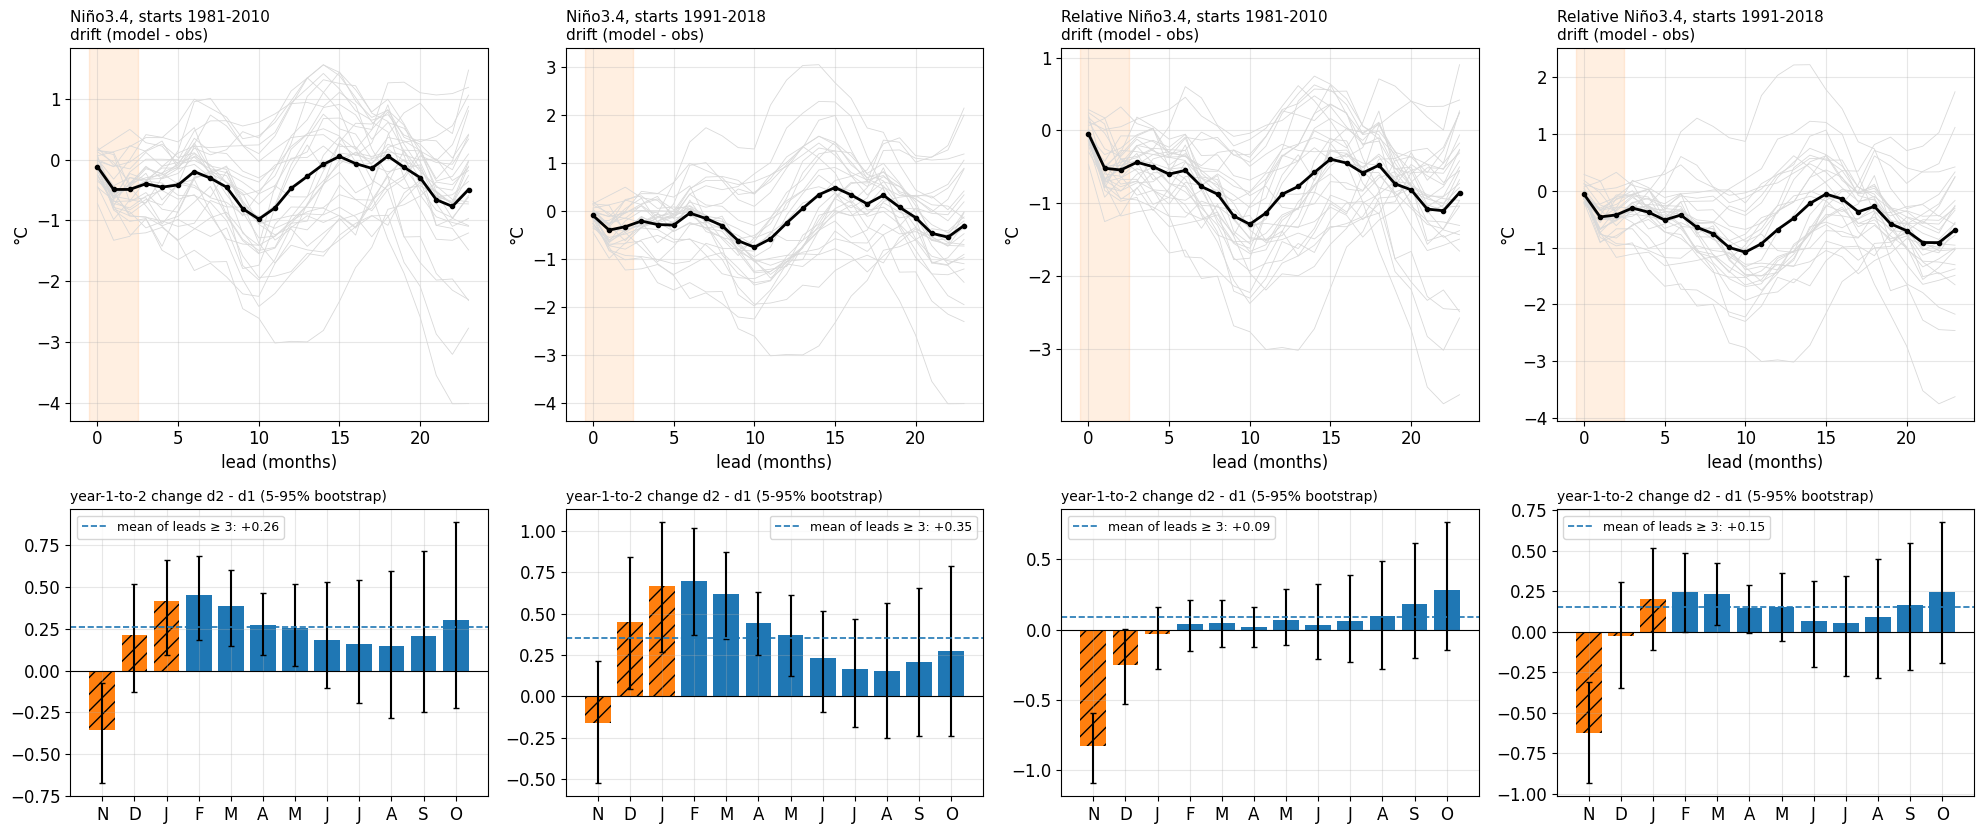

,index,base,starts,"mean d2-d1, leads ≥ 3 (°C/yr)",d2-d1 at lead 0 (Nov),fitted r (leads 0-23),fitted r (leads 3-23)
0,Nino3.4,1981-2010,30,0.26,-0.36,0.98 (T=600),0.23 (T=8)
1,Nino3.4,1991-2018/2020,28,0.35,-0.16,0.64 (T=27),0.08 (T=5)
2,Relative,1981-2010,30,0.09,-0.83,0.00 (T=1),0.98 (T=600)
3,Relative,1991-2018/2020,28,0.15,-0.62,0.00 (T=1),0.44 (T=14)


In [5]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8.5), gridspec_kw={"height_ratios": [1.3, 1]})
rows = []
for col, (kind, base) in enumerate([(k, b) for k in INDICES for b in BASES]):
    per_year, years = drift_per_year(kind, BASES[base]["starts"])
    d = per_year.mean(0)
    rng = np.random.default_rng(0)
    boot = np.array([per_year[rng.integers(0, len(years), len(years))].mean(0) for _ in range(N_BOOT)])
    ax = axes[0, col]
    for p in per_year:
        ax.plot(range(NLEAD_REF), p, color="0.85", lw=0.6)
    ax.plot(range(NLEAD_REF), d, "k-o", ms=3, lw=2)
    ax.axvspan(-0.5, ADJUST_LEADS - 0.5, color="tab:orange", alpha=0.12)
    ax.set_title(f"{INDICES[kind].split(' (')[0]}, starts {base.split('/')[0]}\ndrift (model - obs)", loc="left", fontsize=11)
    ax.set_xlabel("lead (months)")
    ax.set_ylabel("°C")
    ax = axes[1, col]
    delta = d[12:] - d[:12]
    lo, hi = np.percentile(boot[:, 12:] - boot[:, :12], [5, 95], axis=0)
    bars = ax.bar(range(12), delta, color=["tab:orange" if L < ADJUST_LEADS else "tab:blue" for L in range(12)],
                  yerr=[delta - lo, hi - delta], capsize=2)
    for L in range(ADJUST_LEADS):
        bars[L].set_hatch("//")
    ax.axhline(delta[ADJUST_LEADS:].mean(), color="tab:blue", ls="--", lw=1.2,
               label=f"mean of leads ≥ {ADJUST_LEADS}: {delta[ADJUST_LEADS:].mean():+.2f}")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(range(12), [MLAB[MONTH[L] - 1] for L in range(12)])
    ax.set_title("year-1-to-2 change d2 - d1 (5-95% bootstrap)", loc="left", fontsize=10)
    ax.legend(fontsize=9)
    rf, T = fit_r(d)
    rfa, Ta = fit_r(d, ADJUST_LEADS)
    rows.append({"index": kind, "base": base, "starts": len(years), "mean d2-d1, leads ≥ 3 (°C/yr)": round(delta[ADJUST_LEADS:].mean(), 2),
                 "d2-d1 at lead 0 (Nov)": round(delta[0], 2), "fitted r (leads 0-23)": f"{rf:.2f} (T={T:.0f})",
                 f"fitted r (leads {ADJUST_LEADS}-23)": f"{rfa:.2f} (T={Ta:.0f})"})
fig.tight_layout()
save(fig, "year3", "drift_year_change")
plt.show()
display(pd.DataFrame(rows))

### 2. Where the lead-24 step comes from

The anomaly change from lead 23 (Oct 2028) to 24 (Nov 2028) is
(raw forecast change) − (observed climatology change) − (drift change). The model's own Oct-to-Nov change
is larger than observed; within year 2 the drift absorbs it (its change from lead 11 to 12). At the
year-2-to-3 boundary the drift must make the same jump, plus a year of drift change, to keep the anomaly
continuous.

In [6]:
rows = []
for kind in INDICES:
    for base in BASES:
        _, fc, obs = series(kind)
        per_year, _ = drift_per_year(kind, BASES[base]["starts"])
        d = per_year.mean(0)
        clim = month_clim(obs, BASES[base]["clim"])
        f = fc.mean("member").values
        row = {"index": kind, "base": base, "raw forecast 23→24": round(f[24] - f[23], 2),
               "obs clim Oct→Nov": round(clim[11] - clim[10], 2), "drift 11→12 (year 2 start)": round(d[12] - d[11], 2)}
        for method in ("hold (r = 0)", "per-month, r = 1", "adjusted, r = 1"):
            dx, _ = extend(d, method)
            row[f"drift 23→24, {method}"] = round(dx[24] - dx[23], 2)
        rows.append(row)
display(pd.DataFrame(rows))

,index,base,raw forecast 23→24,obs clim Oct→Nov,drift 11→12 (year 2 start),"drift 23→24, hold (r = 0)","drift 23→24, per-month, r = 1","drift 23→24, adjusted, r = 1"
0,Nino3.4,1981-2010,0.32,-0.08,0.32,0.02,-0.34,0.28
1,Nino3.4,1991-2018/2020,0.32,-0.03,0.33,0.05,-0.11,0.40
2,Relative,1981-2010,0.08,-0.22,0.26,-0.02,-0.85,0.07
3,Relative,1991-2018/2020,0.08,-0.17,0.25,0.00,-0.62,0.16


### 3. Year-3 drift methods: the forecast and the step

Ensemble mean (lines) and 10-90% member range (shading) of the 1 Nov 2026 forecast for each method;
grey: DJF. The table gives the step (lead 23 → 24) against the typical month-to-month change of the
ensemble mean over leads 12-35 (median absolute change, the 23→24 pair left out).

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/01_year3_drift_sensitivity/figures/fig_year3_forecast_by_method.png


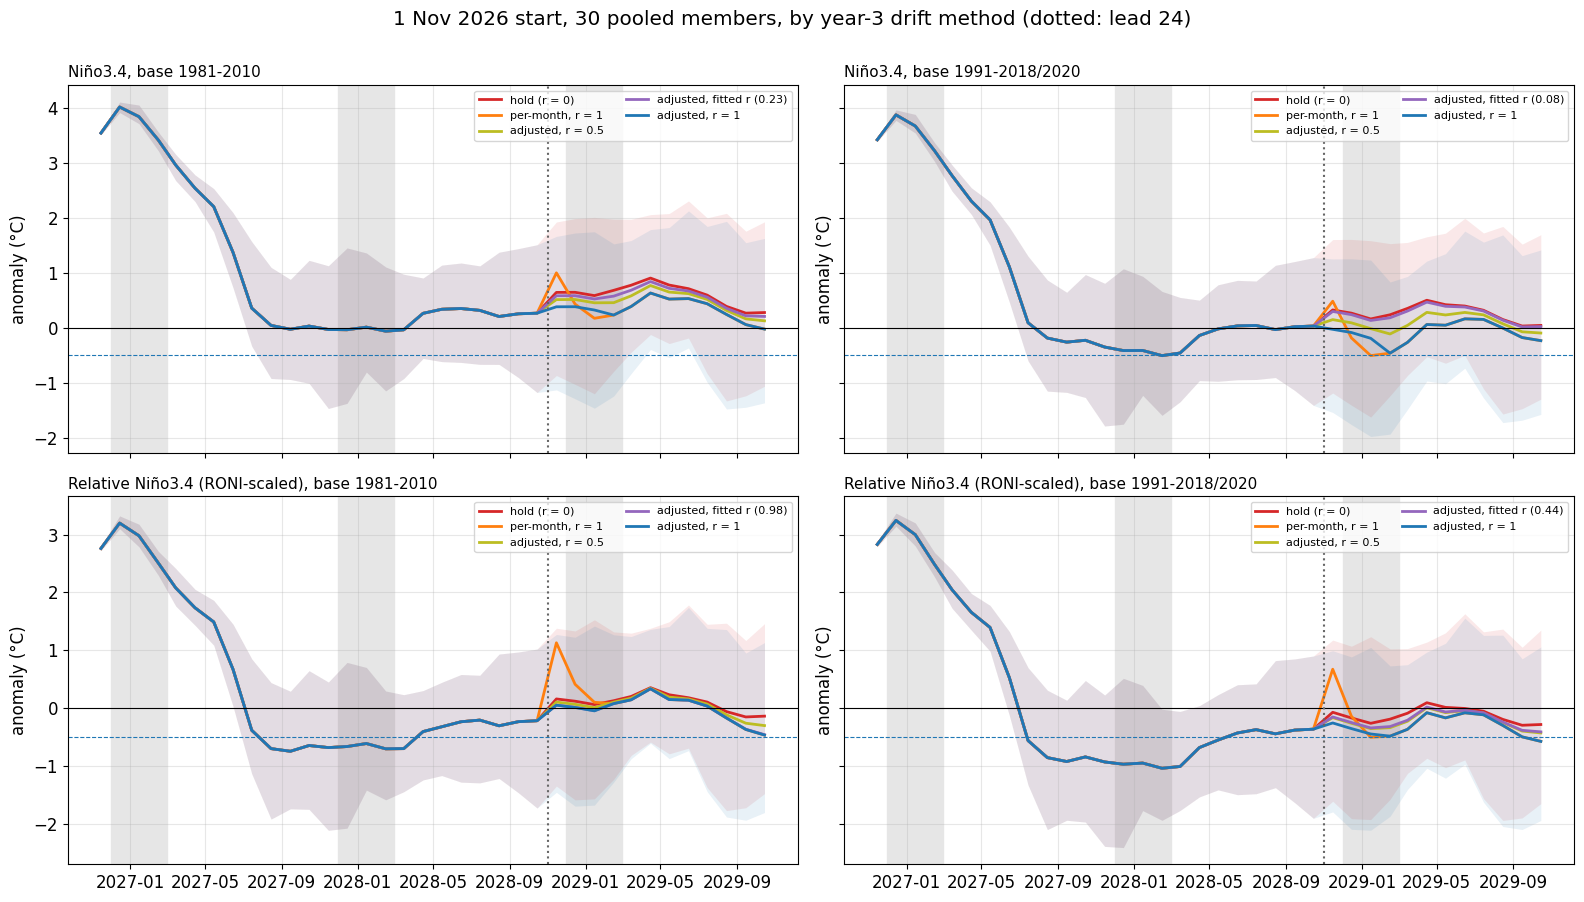

,index,base,method,r,step 23→24 (°C),typical |Δ| (°C)
0,Nino3.4,1981-2010,hold (r = 0),0.00,0.38,0.07
1,Nino3.4,1981-2010,"per-month, r = 1",1.00,0.73,0.08
2,Nino3.4,1981-2010,"adjusted, r = 0.5",0.50,0.25,0.05
3,Nino3.4,1981-2010,"adjusted, fitted r",0.23,0.32,0.06
4,Nino3.4,1981-2010,"adjusted, r = 1",1.00,0.12,0.07
5,Nino3.4,1991-2018/2020,hold (r = 0),0.00,0.29,0.08
6,Nino3.4,1991-2018/2020,"per-month, r = 1",1.00,0.45,0.07
7,Nino3.4,1991-2018/2020,"adjusted, r = 0.5",0.50,0.12,0.06
8,Nino3.4,1991-2018/2020,"adjusted, fitted r",0.08,0.27,0.07
9,Nino3.4,1991-2018/2020,"adjusted, r = 1",1.00,-0.06,0.07


In [7]:
rows = []
x = [target(YEAR, L).to_timestamp() + pd.Timedelta(days=14) for L in range(NLEAD)]
fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True, sharey="row")
for row, kind in enumerate(INDICES):
    for col, base in enumerate(BASES):
        ax = axes[row, col]
        for method in METHODS:
            a, r = forecast_anomaly(kind, base, method)
            em = a.mean(0)
            if method in ("hold (r = 0)", "adjusted, r = 1"):
                ax.fill_between(x, np.percentile(a, 10, 0), np.percentile(a, 90, 0), color=COLORS[method], alpha=0.1, lw=0)
            ax.plot(x, em, color=COLORS[method], lw=2, label=f"{method}" + (f" ({r:.2f})" if "fitted" in method else ""))
            dif = np.abs(np.diff(em[12:]))
            rows.append({"index": kind, "base": base, "method": method, "r": round(r, 2),
                         "step 23→24 (°C)": round(em[24] - em[23], 2),
                         "typical |Δ| (°C)": round(np.median(np.delete(dif, NLEAD_REF - 1 - 12)), 2)})
        ax.axhline(0, color="k", lw=0.8)
        ax.axhline(THRESHOLD, color="tab:blue", ls="--", lw=0.8)
        ax.axvline(x[NLEAD_REF] - pd.Timedelta(days=14), color="0.4", ls=":")
        for first in WINTERS.values():
            ax.axvspan(x[first] - pd.Timedelta(days=14), x[first + 2] + pd.Timedelta(days=14), color="0.9", zorder=0)
        ax.set_title(f"{INDICES[kind]}, base {base}", loc="left", fontsize=11)
        ax.set_ylabel("anomaly (°C)")
        ax.legend(fontsize=8, ncol=2)
fig.suptitle("1 Nov 2026 start, 30 pooled members, by year-3 drift method (dotted: lead 24)", y=1.0)
fig.tight_layout()
save(fig, "year3", "forecast_by_method")
plt.show()
steps = pd.DataFrame(rows)
steps.to_csv(DATA_DIR / "year3_lead24_step.csv", index=False)
display(steps)

### 4. P(La Niña): DJF 2027/28, 2028/29 and both

Fraction of the 30 members with a DJF mean at or below −0.5 °C. The strip plot shows every member's
DJF 2028/29 value (bar: ensemble mean).

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/01_year3_drift_sensitivity/figures/fig_year3_djf2028_members.png


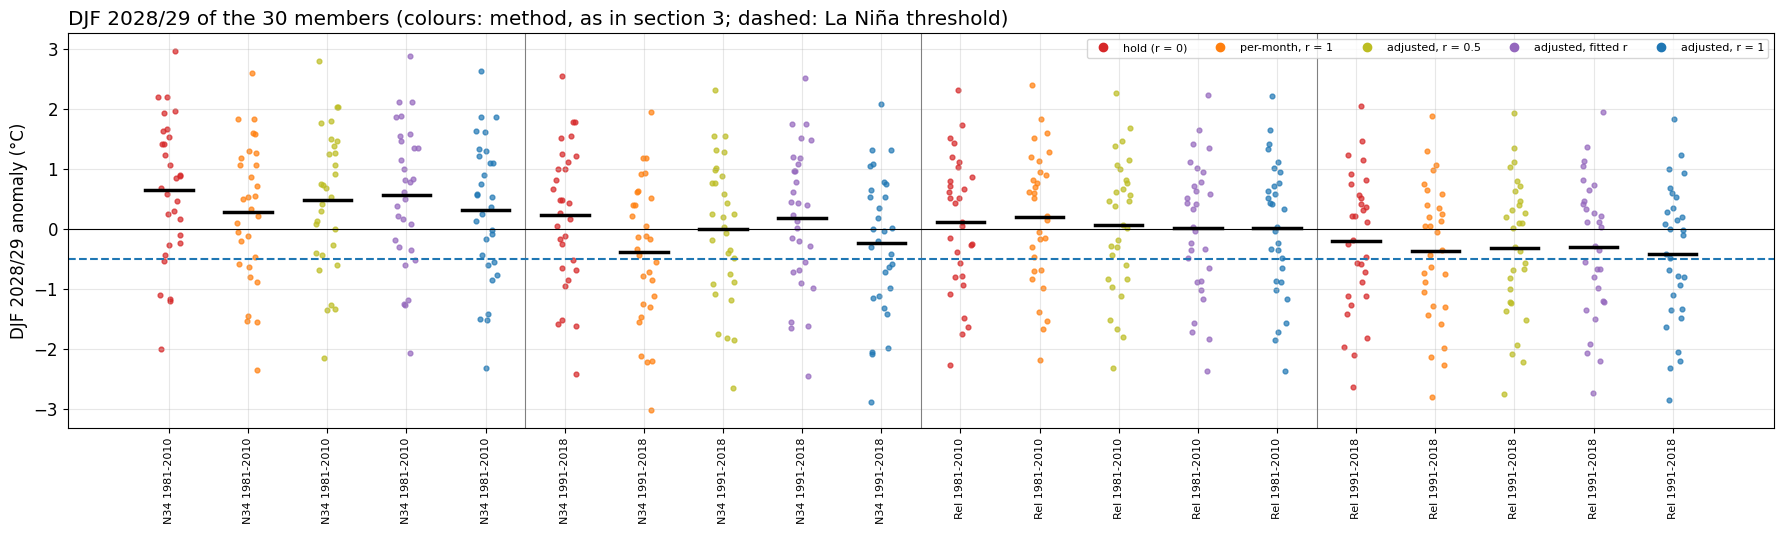

,index,base,method,r,DJF 27/28 mean,P(LN 27/28),DJF 28/29 mean,P(LN 28/29),P(both)
0,Niño3.4,1981-2010,hold (r = 0),0.00,-0.02,0.30,0.64,0.17,0.07
1,Niño3.4,1981-2010,"per-month, r = 1",1.00,-0.02,0.30,0.28,0.27,0.10
2,Niño3.4,1981-2010,"adjusted, r = 0.5",0.50,-0.02,0.30,0.48,0.20,0.10
3,Niño3.4,1981-2010,"adjusted, fitted r",0.23,-0.02,0.30,0.57,0.20,0.10
4,Niño3.4,1981-2010,"adjusted, r = 1",1.00,-0.02,0.30,0.32,0.27,0.10
5,Niño3.4,1991-2018/2020,hold (r = 0),0.00,-0.44,0.57,0.23,0.30,0.17
6,Niño3.4,1991-2018/2020,"per-month, r = 1",1.00,-0.44,0.57,-0.38,0.43,0.27
7,Niño3.4,1991-2018/2020,"adjusted, r = 0.5",0.50,-0.44,0.57,-0.01,0.30,0.17
8,Niño3.4,1991-2018/2020,"adjusted, fitted r",0.08,-0.44,0.57,0.19,0.30,0.17
9,Niño3.4,1991-2018/2020,"adjusted, r = 1",1.00,-0.44,0.57,-0.24,0.40,0.23


In [8]:
rows, strips = [], []
for kind in INDICES:
    for base in BASES:
        for method in METHODS:
            a, r = forecast_anomaly(kind, base, method)
            v = {w: djf(a, first) for w, first in WINTERS.items()}
            ln = {w: v[w] <= THRESHOLD for w in v}
            rows.append({"index": INDICES[kind], "base": base, "method": method, "r": round(r, 2),
                         "DJF 27/28 mean": round(v["2027/28"].mean(), 2), "P(LN 27/28)": round(ln["2027/28"].mean(), 2),
                         "DJF 28/29 mean": round(v["2028/29"].mean(), 2), "P(LN 28/29)": round(ln["2028/29"].mean(), 2),
                         "P(both)": round((ln["2027/28"] & ln["2028/29"]).mean(), 2)})
            strips.append((kind, base, method, v["2028/29"]))
prob = pd.DataFrame(rows)
prob.to_csv(DATA_DIR / "year3_la_nina_probabilities.csv", index=False)

fig, ax = plt.subplots(figsize=(18, 5.5))
rng = np.random.default_rng(1)
ticks = []
for k, (kind, base, method, vals) in enumerate(strips):
    ax.scatter(k + rng.uniform(-0.15, 0.15, vals.size), vals, s=12, color=COLORS[method], alpha=0.7)
    ax.plot([k - 0.3, k + 0.3], [vals.mean()] * 2, color="k", lw=2.5)
    ticks.append(f"{'N34' if kind == 'Nino3.4' else 'Rel'} {base.split('/')[0]}")
    if (k + 1) % len(METHODS) == 0 and k + 1 < len(strips):
        ax.axvline(k + 0.5, color="0.5", lw=0.8)
ax.axhline(THRESHOLD, color="tab:blue", ls="--")
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(len(strips)), ticks, fontsize=8, rotation=90)
ax.set_ylabel("DJF 2028/29 anomaly (°C)")
ax.set_title("DJF 2028/29 of the 30 members (colours: method, as in section 3; dashed: La Niña threshold)", loc="left")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=m) for m, c in COLORS.items()]
ax.legend(handles=handles, fontsize=8, ncol=5, loc="upper right")
fig.tight_layout()
save(fig, "year3", "djf2028_members")
plt.show()
display(prob)

### 5. Base period and trend

Observed (HadISST 1.1) Niño3.4 and tropical-mean anomalies from 1981-2010 (12-month running means), and
the forecast's tropical mean. The tropical-mean warming since the base period is what a standard Niño3.4
anomaly carries and the relative index removes.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/01_year3_drift_sensitivity/figures/fig_year3_tropical_trend.png


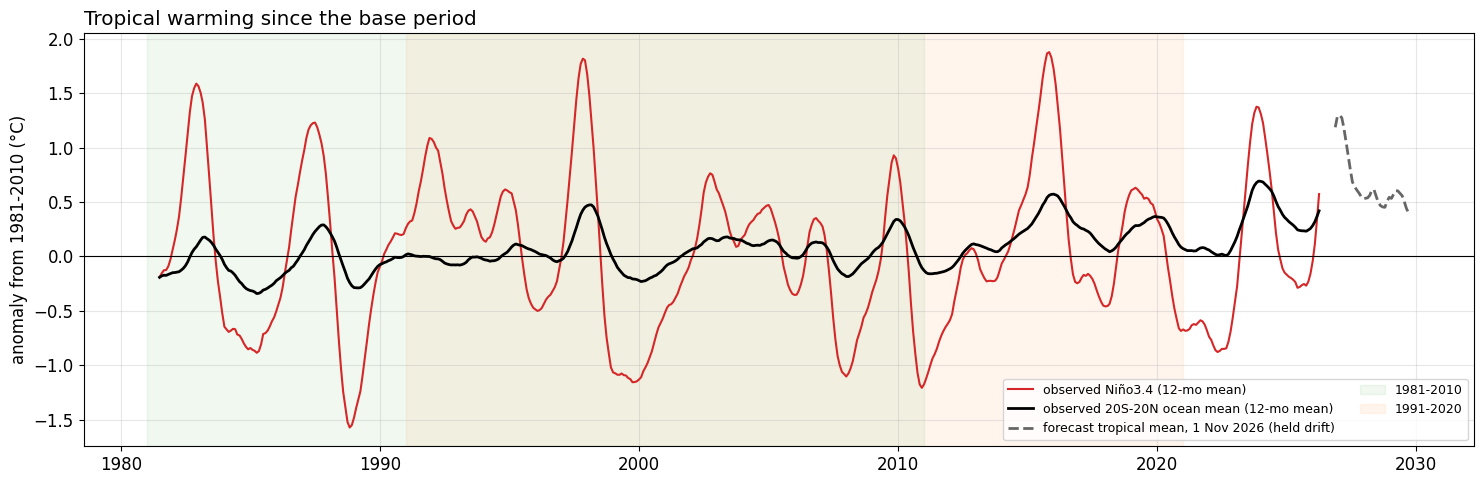

1991-2020 minus 1981-2010 observed climatology (annual mean, °C): {'Niño3.4': 0.06, 'tropical mean': 0.09, 'relative': -0.03}


In [9]:
base0 = BASES["1981-2010"]["clim"]
an = OBS - month_clim(OBS, base0).reindex(OBS.index.month).values
at = OBS_T - month_clim(OBS_T, base0).reindex(OBS_T.index.month).values
t = an.index.to_timestamp()
_, fc_t, _ = D["ref_trop"], D["fc_trop"], None
per_year_n, _ = drift_per_year("Nino3.4", BASES["1981-2010"]["starts"])
per_year_r, _ = drift_per_year("Relative", BASES["1981-2010"]["starts"])
d_trop = np.r_[(per_year_n - per_year_r).mean(0), (per_year_n - per_year_r).mean(0)[12:24]]   # held, r = 0
fc_trop_anom = D["fc_trop"].values - (month_clim(OBS_T, base0).loc[MONTH].values + d_trop)[None, :]
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(t, an.rolling(12, center=True).mean(), color="tab:red", lw=1.5, label="observed Niño3.4 (12-mo mean)")
ax.plot(t, at.rolling(12, center=True).mean(), color="k", lw=2, label="observed 20S-20N ocean mean (12-mo mean)")
ax.plot(x, fc_trop_anom.mean(0), color="0.4", ls="--", lw=2, label="forecast tropical mean, 1 Nov 2026 (held drift)")
for b, c in [((1981, 2010), "tab:green"), ((1991, 2020), "tab:orange")]:
    ax.axvspan(pd.Timestamp(b[0], 1, 1), pd.Timestamp(b[1], 12, 31), color=c, alpha=0.07, label=f"{b[0]}-{b[1]}")
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("anomaly from 1981-2010 (°C)")
ax.legend(fontsize=9, ncol=2)
ax.set_title("Tropical warming since the base period", loc="left")
fig.tight_layout()
save(fig, "year3", "tropical_trend")
plt.show()
shift = {k: round(float((month_clim(s, (1991, 2020)) - month_clim(s, (1981, 2010))).mean()), 2)
         for k, s in [("Niño3.4", OBS), ("tropical mean", OBS_T), ("relative", OBS - OBS_T)]}
print("1991-2020 minus 1981-2010 observed climatology (annual mean, °C):", shift)

### Findings

**1. The lead-24 step is not the held drift jumping; it is the forecast's own seasonal cycle meeting a drift that
stopped changing.** With the drift held ($r = 0$) the drift is continuous across lead 23→24 (+0.02 °C for Niño3.4).
The step comes from the raw forecast, which rises +0.32 °C from Oct to Nov 2028: the model's Oct-to-Nov change is
larger than observed (+0.24 in the Reanalysis climatology against −0.08 observed), and within year 2 the drift
absorbs it (+0.32 from lead 11 to 12). At the year-2-to-3 boundary a held drift does not make that jump.

**2. The drift does keep changing in year 2, so holding it biases year 3 warm** (the concern is right in
substance). After the initial adjustment, the Niño3.4 drift rises from year 1 to year 2 by about +0.26 °C/yr
(1981-2010 starts) or +0.35 °C/yr (1991-2018), fairly uniformly over the target months (section 1).

**3. The per-month formula as proposed makes the step worse** (Niño3.4 +0.73 °C, relative +1.34 °C at $r = 1$).
For November, $d_1$ is lead 0, the initialization month, which has hardly drifted, so $d_2 - d_1$ there
(−0.36 °C; −0.83 for the relative index) is the initial adjustment, not the slow drift, and carrying it into
year 3 pushes November the wrong way. Taking the year-to-year change from leads ≥ 3 only (*adjusted*) and
continuing it linearly ($r = 1$) removes most of the step for Niño3.4: +0.12 °C (1981-2010) and −0.06 °C
(1991-2018), against a typical month-to-month change of 0.07 °C.

**4. The exponential fit cannot pin down $r$ from 24 months**: $T$ ranges from 5 to 600 months depending on
index, base and leads used, so the fitted $r$ is not a usable estimate. $r$ should be quoted as a range
(0 to 1), with the adjusted $r = 1$ as the method that passes the step check.

**5. The relative index removes the trend but not the step.** Its drift barely changes after year 1
(+0.09 to +0.15 °C/yr), and it keeps a step of +0.1 to +0.4 °C, now mostly from the observed climatology
(the relative index falls −0.2 °C from Oct to Nov in observations; the model does not). Its P(La Niña 2028/29)
is almost insensitive to the year-3 method (0.27-0.30 with the 1981-2010 base, 0.40-0.43 with 1991-2018).

**6. The base period matters more than the year-3 method, and through the drift, not the observed climatology.**
The 1991-2020 observed climatology is only +0.06 °C warmer than 1981-2010 in Niño3.4 (+0.09 in the tropical
mean), yet switching to the 1991-2018 starts cools DJF 2027/28 by 0.4 °C: the model's drift differs between
the two sets of start years. That non-stationary drift is itself a source of uncertainty.

**7. P(La Niña)** (30 members, so each value has a sampling uncertainty of about ±0.08):

| | P(LN 2027/28) | P(LN 2028/29) | P(both) |
|---|---|---|---|
| Niño3.4, held drift (current) | 0.30 / 0.57 | 0.17 / 0.30 | 0.07 / 0.17 |
| Niño3.4, adjusted, $r = 1$ | 0.30 / 0.57 | 0.27 / 0.40 | 0.10 / 0.23 |
| Relative (RONI), adjusted, $r = 1$ | 0.60 / 0.73 | 0.30 / 0.43 | 0.17 / 0.30 |

(first value: 1981-2010 base; second: 1991-2018/2020.) Across all indices, bases and methods that pass the
step check, P(La Niña 2028/29) is 0.27-0.43 and P(double La Niña) 0.10-0.30; the current method (held drift,
1981-2010 Niño3.4) is at the low end, 0.17.

**Next:** a drift model that separates the initial adjustment from the slow drift using all
Reanalysis start months, and a check of the year-3 extrapolation where it can be tested (predict year 2 of the
Reanalysis from year 1 by the same rule).